# Finnish corporate credit-risk scenarios

A learning exercise using public aggregate lending exposures and Finnish economic context. How do exposure composition and explicit recession assumptions affect an illustrative one-year loss?

| Observed | Assumed | Derived |
|---|---|---|
| Published loan balances and economic indicators | Baseline PD/LGD, adverse multipliers and recovery deterioration | Exposure weights, conditional losses and sensitivity |

PD and LGD are not estimated from the public indicators. This is not a Nordea portfolio or an IFRS 9 model.

In [1]:
from pathlib import Path
import json, os
ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Run from project root or notebooks/'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplconfig'))
import pandas as pd
from IPython.display import display, Markdown
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
from credit_scenarios.reporting import (load_inputs, result_tables, plot_context, plot_losses, plot_sensitivity)
records, config, lending_meta, macro = load_inputs(ROOT)
result, segments, grid = result_tables(records, config)

## 1. The observed exposure snapshot

Reference period: **2025Q4**. Amounts below are euros. Source documentation records coverage, industry mappings, exclusions and the conversion from loan balances to the EAD proxy. Existing non-performing balances are retained; this is a loss proxy on total stocks. Observation and retrieval dates are distinct.

In [2]:
display(pd.read_csv(ROOT / 'data/processed/exposures.csv'))
display(Markdown('Source definitions: [lending](../docs/SOURCES_LENDING.md) · [economic context](../docs/SOURCES_MACRO.md)'))

,sector,exposure_eur,source_industry,reference_date,value_status,exposure_basis
0,manufacturing,9.737497e+09,C,2025-12-31,observed,outstanding stock; NPLs not deducted
1,construction,2.559938e+09,F,2025-12-31,observed,outstanding stock; NPLs not deducted
2,real_estate,1.626627e+10,L,2025-12-31,observed,outstanding stock; NPLs not deducted
3,other,3.435184e+10,residual,2025-12-31,derived residual,outstanding stock; NPLs not deducted


Source definitions: [lending](../docs/SOURCES_LENDING.md) · [economic context](../docs/SOURCES_MACRO.md)

## 2. The economic context

Observed time series describe recent conditions. Bankruptcy petitions measure business distress in a different population from bank borrowers. Counts depend on industry size and are not default rates; pandemic-era policy changes also affect comparisons. These indicators do not feed a fitted PD or LGD regression.

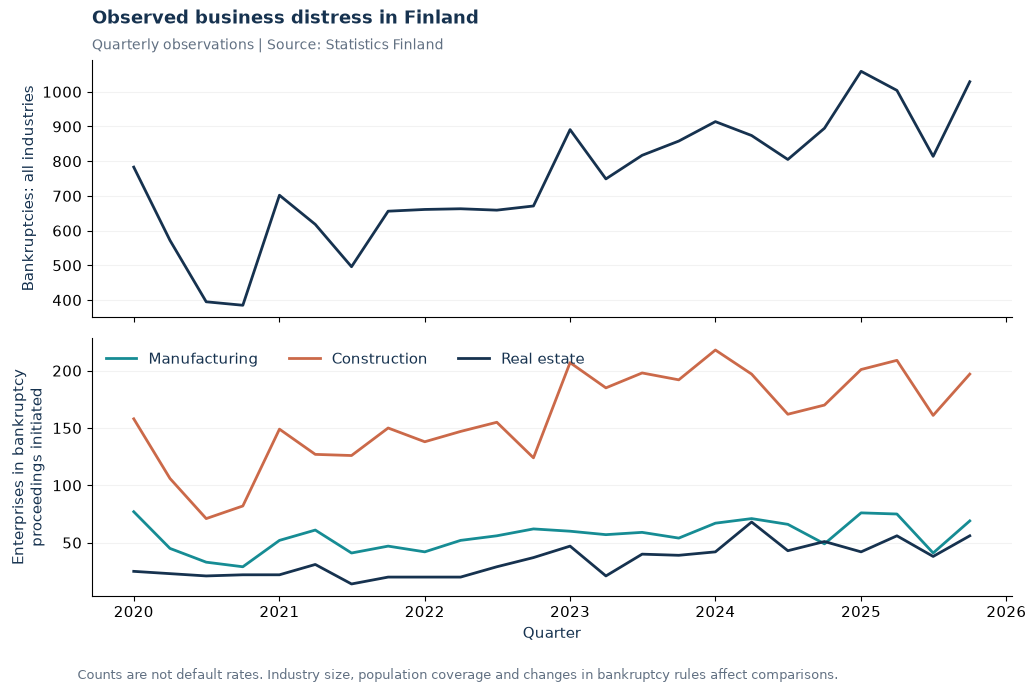

In [3]:
fig = plot_context(macro)
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

## 3. From the recession narrative to explicit credit assumptions

We consider a hypothetical contraction in activity, weaker cash flows and deterioration in collateral recovery. The configuration records the chosen translation into PD and LGD. The baseline is a reference set of assumptions, not an official economic forecast. The default configuration shares starting PD and LGD so exposure weights and imposed stress differences can be inspected directly.

$$EL_s = EAD_s \times PD_s \times LGD_s,\qquad EL = \sum_s EL_s.$$

Valid stressed probabilities are capped at 100%; invalid starting parameters are rejected. Cap counts are reported.

In [4]:
assumptions = pd.DataFrame(config['sectors']).T
assumptions.index.name = 'sector'
display(assumptions)
display(pd.Series(result['totals'], name='portfolio'))

,baseline_pd,baseline_lgd,adverse_pd_multiplier,adverse_lgd_uplift
sector,,,,
manufacturing,0.015,0.4,2.0,0.05
construction,0.015,0.4,3.0,0.10
real_estate,0.015,0.4,3.0,0.15
other,0.015,0.4,2.0,0.05


exposure_eur          6.291554e+10
baseline_loss_eur     3.774932e+08
adverse_loss_eur      1.055395e+09
increase_eur          6.779015e+08
baseline_loss_rate    6.000000e-03
adverse_loss_rate     1.677479e-02
pd_cap_count          0.000000e+00
lgd_cap_count         0.000000e+00
Name: portfolio, dtype: float64

## 4. Results and contributions

Compare loss amounts and loss rates. A sector can account for a large loss because of its exposure, its assumed credit deterioration, or both. Contribution shares allocate the change in euro losses.

,sector,exposure_eur,exposure_share,baseline_loss_eur,adverse_loss_eur,increase_eur,adverse_loss_rate,share_of_increase
0,manufacturing,9.737497e+09,0.154771,5.842498e+07,1.314562e+08,7.303123e+07,0.01350,0.107731
1,construction,2.559938e+09,0.040688,1.535963e+07,5.759860e+07,4.223897e+07,0.02250,0.062308
2,real_estate,1.626627e+10,0.258541,9.759759e+07,4.025901e+08,3.049925e+08,0.02475,0.449907
3,other,3.435184e+10,0.545999,2.061110e+08,4.637498e+08,2.576388e+08,0.01350,0.380053


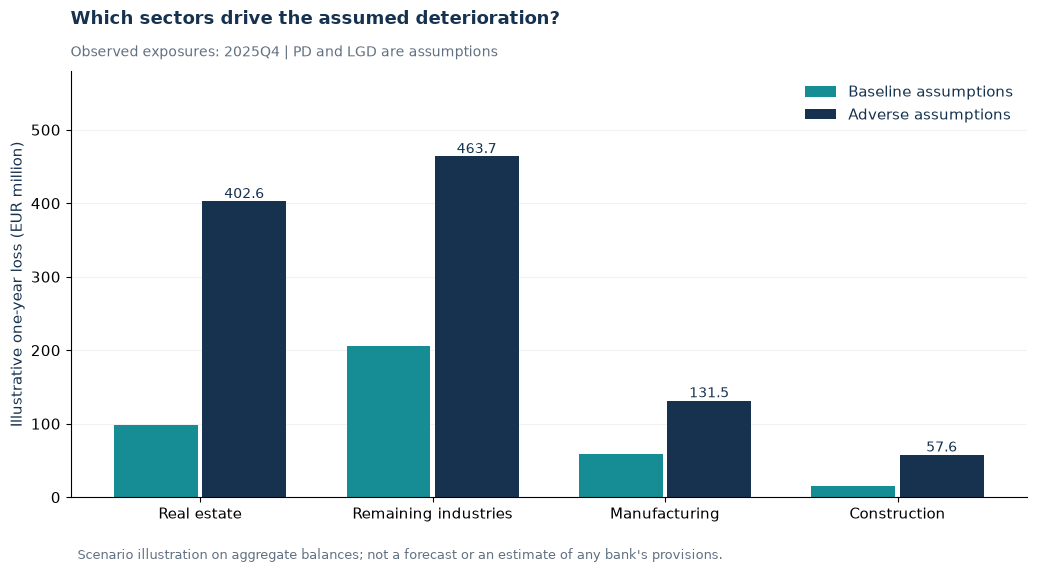

In [5]:
display(segments[['sector', 'exposure_eur', 'exposure_share', 'baseline_loss_eur', 'adverse_loss_eur', 'increase_eur', 'adverse_loss_rate', 'share_of_increase']])
fig = plot_losses(segments, '2025Q4')
display(fig)
plt.close(fig)

## 5. Sensitivity to uncertain parameters

This separate grid applies the same PD multiplier and LGD uplift to every industry's baseline. It is not a confidence interval and does not reproduce the industry-specific adverse scenario.

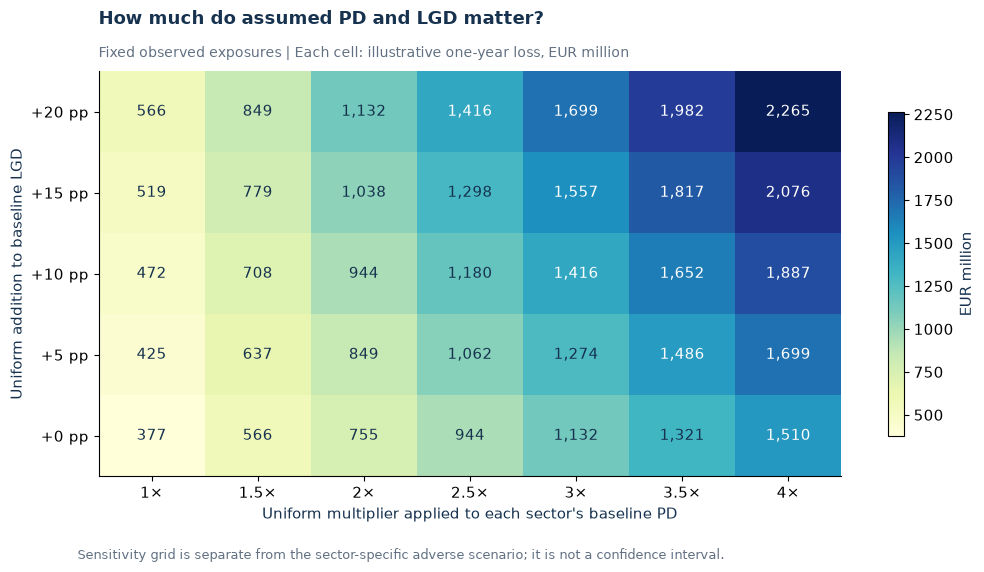

,pd_multiplier,lgd_uplift,loss_eur,loss_rate
0,1.0,0.00,3.774932e+08,0.006000
1,1.0,0.05,4.246799e+08,0.006750
2,1.0,0.10,4.718665e+08,0.007500
3,1.0,0.15,5.190532e+08,0.008250
4,1.0,0.20,5.662398e+08,0.009000
5,1.5,0.00,5.662398e+08,0.009000
6,1.5,0.05,6.370198e+08,0.010125
7,1.5,0.10,7.077998e+08,0.011250
8,1.5,0.15,7.785798e+08,0.012375
9,1.5,0.20,8.493598e+08,0.013500


In [6]:
fig = plot_sensitivity(grid)
display(fig)
plt.close(fig)
display(grid[['pd_multiplier', 'lgd_uplift', 'loss_eur', 'loss_rate']])

## 6. Interpretation


**Question.** Which industries contribute most to an illustrative one-year loss increase, given observed lending exposures and explicit recession assumptions?

**Evidence.** The exposure snapshot is 2025Q4: **EUR 62.916 billion** in outstanding loans to domestic non-financial corporations, excluding housing corporations. Reporters are MFIs excluding Bank of Finland; all currencies are expressed in euros. Statistics Finland bankruptcy counts provide historical context. See [lending definitions](../docs/SOURCES_LENDING.md) and [economic context](../docs/SOURCES_MACRO.md).

**Assumptions.** Each industry starts with the same assumed 1.50% one-year PD and 40.0% LGD. The adverse PD multipliers and LGD increases are chosen assumptions, disclosed in the [configuration](../config/scenarios.json), rather than fitted estimates. Exposures remain fixed. **Existing non-performing balances are retained and are not separately modelled.** This is a loss proxy on outstanding stocks, not an estimate of future losses on a performing-loan portfolio.

**Results.** Baseline illustrative loss is **EUR 377.5 million** (0.60% of exposure). Adverse loss is **EUR 1,055.4 million** (1.68%), a change of **EUR 677.9 million**. Adverse loss is 2.80 times baseline. **Real estate** contributes the largest euro increase: **EUR 305.0 million**, or 45.0% of the net increase. The ranking reflects exposure weights and imposed stress parameters, rather than an empirically measured ranking of borrower risk. The remaining-industries group is a heterogeneous residual including unclassified industries.

**Uncertainty.** The heatmap varies a common PD multiplier and LGD uplift while holding exposures fixed. It gives conditional outcomes, not a confidence interval, and differs from the industry-specific adverse scenario. Cap counts are reported. PD and LGD enter multiplicatively, so simultaneous deterioration matters.

**What to investigate next.** Obtain one-year default transitions, starting credit states, recoveries and their timing, collateral and loan-to-value distributions, and exposure changes at default. Investigate variation within industries. A longer history and out-of-sample validation would be required to estimate macro-to-credit relationships. Bankruptcy counts and NPL ratios cannot substitute directly for one-year PD.

**Limits.** This exercise does not estimate Nordea's portfolio, IFRS 9 provisions, regulatory capital or tail losses. Economic indicators provide context and do not calibrate PD/LGD. Source revisions, reporting populations and aggregation limit inference. Numerical traceability is available in the [notebook](../notebooks/analysis.ipynb), [results](../outputs/sector_results.csv) and [manifest](../outputs/run_manifest.json).


## 7. Reproduce and challenge the result

Run python scripts/build.py from the project root after installing the documented environment. It runs tests, rebuilds results and charts, and executes this notebook in a fresh Python kernel using local snapshots. Live data refresh is separate.

Source metadata records queries, retrieval dates and hashes; outputs/run_manifest.json records input/code hashes and package versions. Automated checks cover arithmetic, validation, caps, monotonicity and snapshot consistency. They check implementation, not empirical model validity.